<a id="1"></a>

<h1 style='background:#007fff;border:0; color:white;
box-shadow: 10px 10px 5px 0px rgba(0,0,0,0.25);
    transform: rotateX(10deg); border-radius: 25px;
    '><center>
        Machine Learning Classification 
    </center>
</h1>
> Prepared by: Tanvir Anjom Siddique

> Portfolio: [tanvirsweb.github.io](https://tanvirsweb.github.io)

**Dataset:** Wisconsin Diagnostic Breast Cancer, loaded directly from `scikit-learn`.

This notebook includes exploratory data analysis, missing-value handling, outlier screening and robust scaling, correlation-based feature removal using a strict absolute-correlation threshold above 0.95, feature selection, stratified train/test splitting, a broad set of classical machine-learning classifiers, cross-validation, classification metrics, confusion-matrix heatmaps, ROC and precision-recall curves, class-wise F1 plots, learning curves, calibration and threshold plots, model-size and complexity proxies, and SHAP explanations for the selected model when SHAP is installed.

The target is remapped so **malignant = 1** and **benign = 0**. Detection rate is reported as malignant-class recall (sensitivity).

**Research cautions:** Do not choose a model based on test-set results in a final study. Use cross-validation on the training set for model selection, then evaluate the locked model on the untouched test set. Classical estimators do not have a universally comparable FLOP count or neural-network-style trainable parameter count. This notebook reports FLOPs as unavailable rather than inventing numbers, and reports transparent complexity proxies such as stored numeric values, tree nodes, serialized model size, and measured prediction time.


<a id="1"></a>

<h1 style='background:#007fff;border:0; color:white;
box-shadow: 10px 10px 5px 0px rgba(0,0,0,0.25);
    transform: rotateX(10deg); border-radius: 25px;
    '><center>
        🛠️ Universal Requirements Generator
    </center>
</h1>

<br>

> Generates a clean `environmentsetup.txt` compatible with Anaconda, Kaggle, and Google Colab by stripping local file paths (`@ file://`) and excluding massive, platform-specific libraries.


In [3]:
!python --version

Python 3.13.5


In [2]:
# Run VSCode or other application as Administrator to get full environment information
# !pip list --format=freeze
# Export your local packages to the file
!pip list --format=freeze > environmentsetup.txt

# Install the packages from that file 
# !pip install -r environmentsetup.txt


## 1. Imports and experiment configuration


In [1]:
import os
import sys
import time
import json
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from IPython.display import display, Markdown
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, log_loss, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve, matthews_corrcoef,
    cohen_kappa_score, brier_score_loss
)
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier, Perceptron, PassiveAggressiveClassifier
from sklearn.tree import DecisionTreeClassifier, ExtraTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier,
    GradientBoostingClassifier, AdaBoostClassifier, BaggingClassifier,
    RandomForestRegressor, VotingClassifier, StackingClassifier, RandomForestClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC, NuSVC
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
TEST_SIZE = 0.20
CORRELATION_THRESHOLD = 0.95
OUTPUT_DIR = Path("classification_research_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")

print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("Platform:", platform.platform())
print("Output directory:", OUTPUT_DIR.resolve())

Python: 3.13.5
scikit-learn: 1.6.1
Platform: Windows-11-10.0.26300-SP0
Output directory: D:\gitProjectsTanvirAnjomSiddique\Notes_and_Practice_Code\Data_Mining_and_WareHousing_CSE4250_BAUET\Data_Mining_and_WareHousing_CSE4250_BAUET\classification_research_outputs


## 2. Load the dataset and define the positive class


In [2]:
dataset = load_breast_cancer(as_frame=True)
X_raw = dataset.data.copy()
y_original = dataset.target.copy()

# scikit-learn encodes malignant as 0 and benign as 1.
# Remap so malignant is the positive class, which is useful for sensitivity/detection-rate reporting.
y = (y_original == 0).astype(int).rename("malignant")
class_names = ["benign", "malignant"]

print("Dataset:", dataset.DESCR.splitlines()[0])
print("Rows:", X_raw.shape[0])
print("Original feature count:", X_raw.shape[1])
print("Target mapping: 0 = benign, 1 = malignant")
display(X_raw.head())

Dataset: .. _breast_cancer_dataset:
Rows: 569
Original feature count: 30
Target mapping: 0 = benign, 1 = malignant


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 3. Dataset statistics


In [3]:
summary = pd.DataFrame({
    "Statistic": [
        "Samples", "Original features", "Target classes", "Duplicate feature rows",
        "Missing feature values", "Numeric features", "Positive class"
    ],
    "Value": [
        len(X_raw), X_raw.shape[1], y.nunique(), int(X_raw.duplicated().sum()),
        int(X_raw.isna().sum().sum()), X_raw.select_dtypes(include=np.number).shape[1],
        "malignant"
    ]
})
display(summary)
display(X_raw.describe().T.round(4))

,Statistic,Value
0,Samples,569
1,Original features,30
2,Target classes,2
3,Duplicate feature rows,0
4,Missing feature values,0
5,Numeric features,30
6,Positive class,malignant


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.1273,3.5240,6.9810,11.7000,13.3700,15.7800,28.1100
mean texture,569.0,19.2896,4.3010,9.7100,16.1700,18.8400,21.8000,39.2800
mean perimeter,569.0,91.9690,24.2990,43.7900,75.1700,86.2400,104.1000,188.5000
mean area,569.0,654.8891,351.9141,143.5000,420.3000,551.1000,782.7000,2501.0000
mean smoothness,569.0,0.0964,0.0141,0.0526,0.0864,0.0959,0.1053,0.1634
mean compactness,569.0,0.1043,0.0528,0.0194,0.0649,0.0926,0.1304,0.3454
mean concavity,569.0,0.0888,0.0797,0.0000,0.0296,0.0615,0.1307,0.4268
mean concave points,569.0,0.0489,0.0388,0.0000,0.0203,0.0335,0.0740,0.2012
mean symmetry,569.0,0.1812,0.0274,0.1060,0.1619,0.1792,0.1957,0.3040
mean fractal dimension,569.0,0.0628,0.0071,0.0500,0.0577,0.0615,0.0661,0.0974


## 4. Class distribution


,Class,Count,Percentage
0,benign,357,62.74
1,malignant,212,37.26


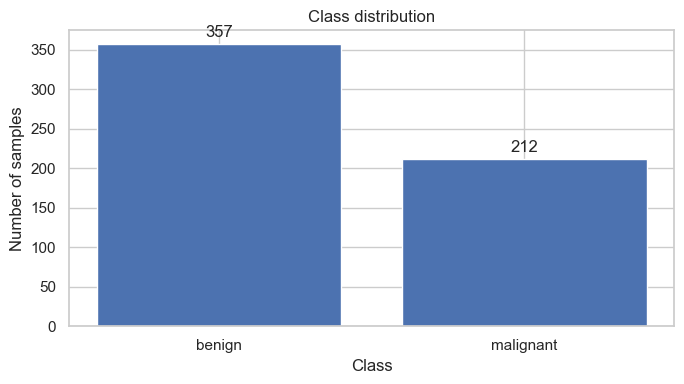

In [4]:
class_counts = y.map({0: "benign", 1: "malignant"}).value_counts().reindex(class_names)
class_distribution = pd.DataFrame({
    "Class": class_counts.index,
    "Count": class_counts.values,
    "Percentage": (100 * class_counts.values / len(y)).round(2)
})
display(class_distribution)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(class_distribution["Class"], class_distribution["Count"])
ax.bar_label(bars, fmt="%.0f", padding=3)
ax.set_title("Class distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Number of samples")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Missing values and duplicate-row review


In [5]:
missing_summary = pd.DataFrame({
    "Missing count": X_raw.isna().sum(),
    "Missing percent": (100 * X_raw.isna().mean()).round(3)
}).sort_values("Missing count", ascending=False)
display(missing_summary)
print("Duplicate feature rows:", int(X_raw.duplicated().sum()))
print("Policy: impute missing numeric values using the training-set median inside each model pipeline.")
print("Duplicate rows are reported but not automatically removed because duplicate measurements need provenance review.")

,Missing count,Missing percent
mean radius,0,0.0
mean texture,0,0.0
mean perimeter,0,0.0
mean area,0,0.0
mean smoothness,0,0.0
mean compactness,0,0.0
mean concavity,0,0.0
mean concave points,0,0.0
mean symmetry,0,0.0
mean fractal dimension,0,0.0


Duplicate feature rows: 0
Policy: impute missing numeric values using the training-set median inside each model pipeline.
Duplicate rows are reported but not automatically removed because duplicate measurements need provenance review.


## 6. Outlier screening


,IQR outlier count,IQR outlier percent
area error,65,11.42
radius error,38,6.68
perimeter error,38,6.68
worst area,35,6.15
smoothness error,30,5.27
fractal dimension error,28,4.92
compactness error,28,4.92
symmetry error,27,4.75
mean area,25,4.39
worst fractal dimension,24,4.22


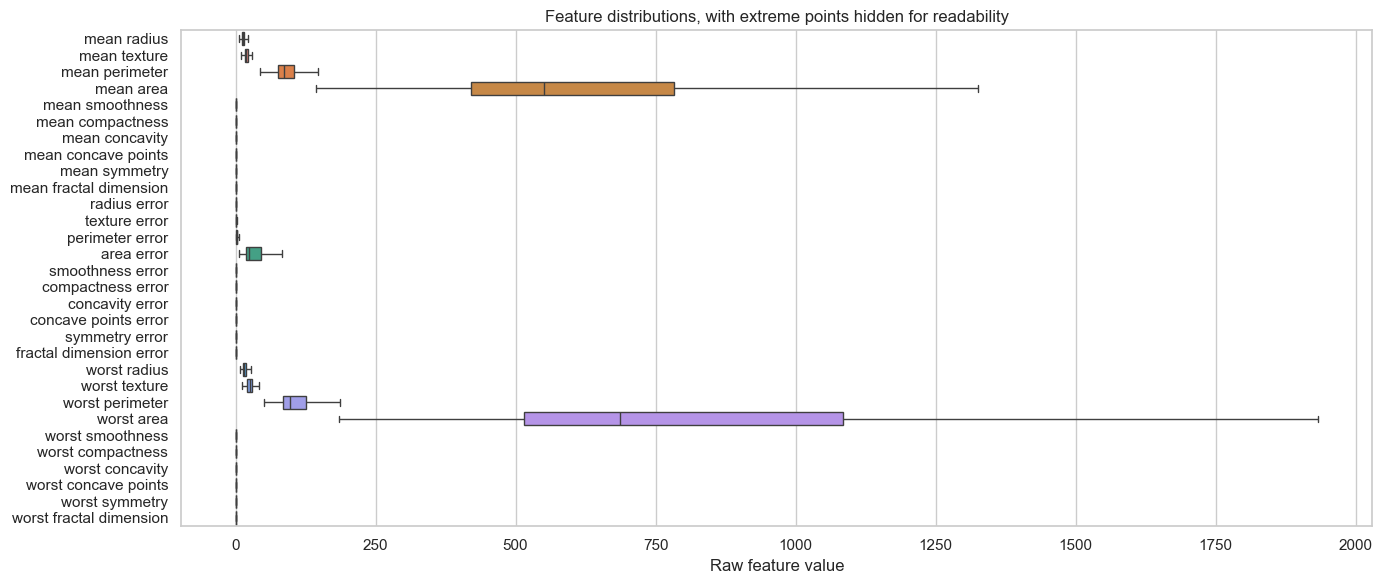

IQR flags are descriptive only. They are not automatically deleted because extreme clinical measurements may be valid.
RobustScaler is used in scaled pipelines to reduce sensitivity to extreme values.


In [6]:
q1 = X_raw.quantile(0.25)
q3 = X_raw.quantile(0.75)
iqr = q3 - q1
outlier_mask = (X_raw < (q1 - 1.5 * iqr)) | (X_raw > (q3 + 1.5 * iqr))
outlier_summary = pd.DataFrame({
    "IQR outlier count": outlier_mask.sum(),
    "IQR outlier percent": (100 * outlier_mask.mean()).round(2)
}).sort_values("IQR outlier count", ascending=False)
display(outlier_summary)

fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=X_raw, orient="h", showfliers=False, ax=ax)
ax.set_title("Feature distributions, with extreme points hidden for readability")
ax.set_xlabel("Raw feature value")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_boxplots.png", dpi=300, bbox_inches="tight")
plt.show()

print("IQR flags are descriptive only. They are not automatically deleted because extreme clinical measurements may be valid.")
print("RobustScaler is used in scaled pipelines to reduce sensitivity to extreme values.")

## 7. Correlation analysis and removal of highly correlated features


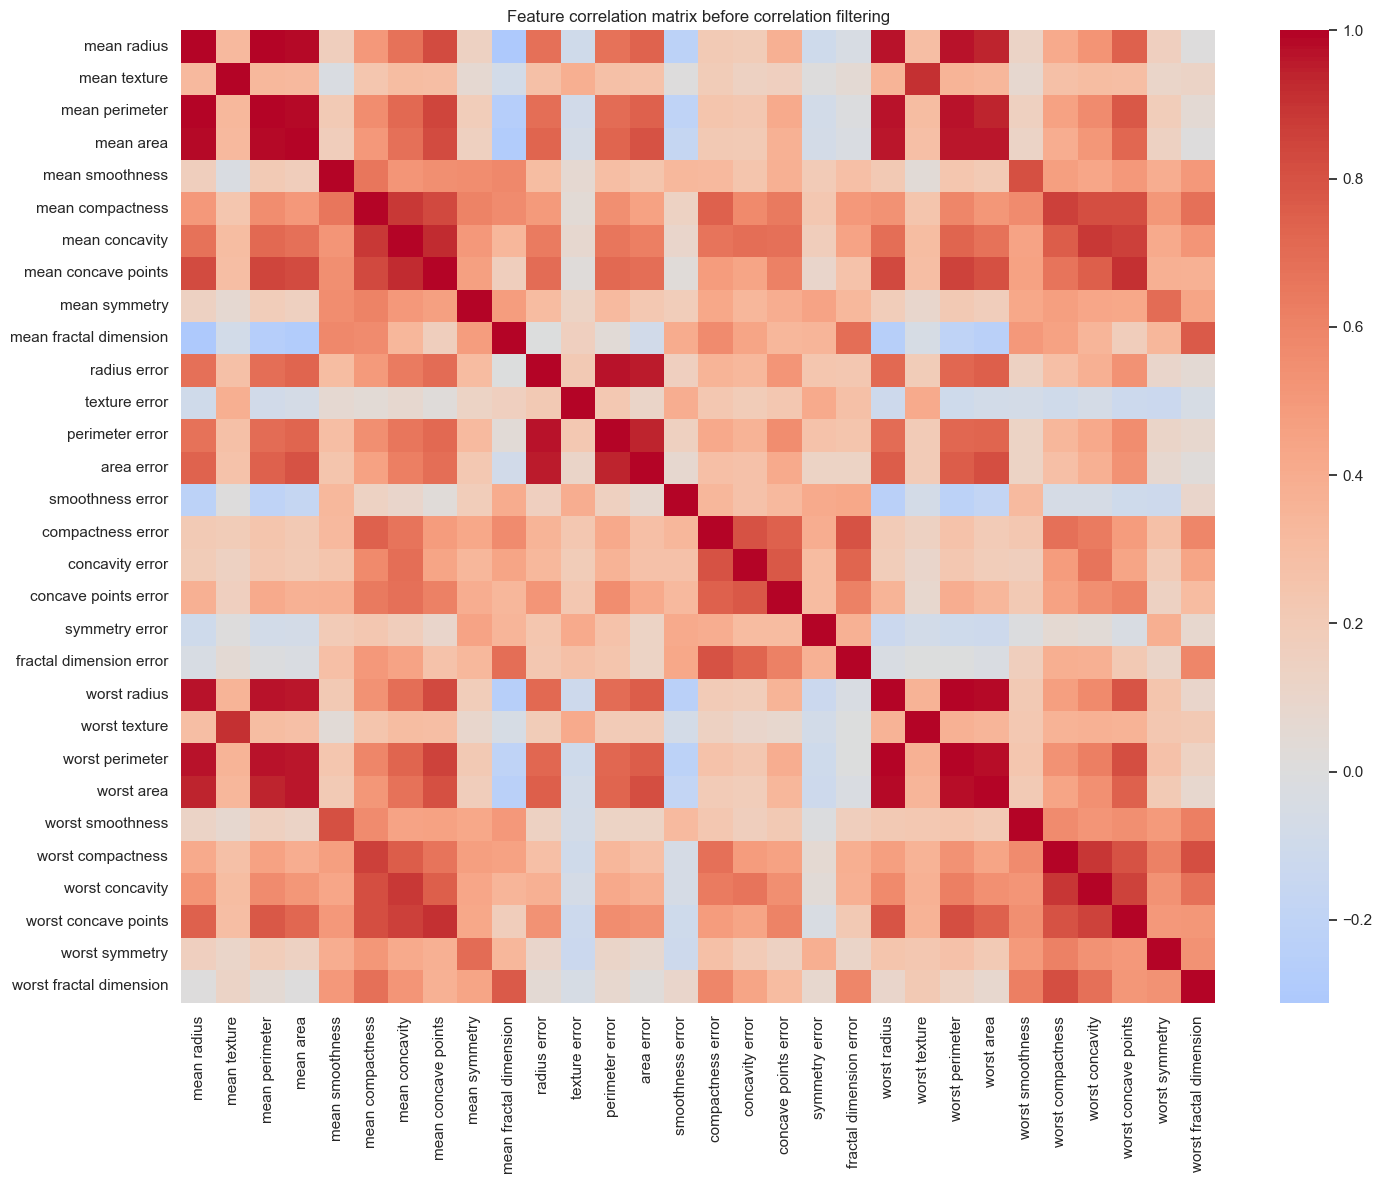

,Feature 1,Feature 2,Correlation,Absolute correlation
1,mean radius,mean perimeter,0.997855,0.997855
391,worst radius,worst perimeter,0.993708,0.993708
2,mean radius,mean area,0.987357,0.987357
57,mean perimeter,mean area,0.986507,0.986507
392,worst radius,worst area,0.984015,0.984015
407,worst perimeter,worst area,0.977578,0.977578
246,radius error,perimeter error,0.972794,0.972794
76,mean perimeter,worst perimeter,0.970387,0.970387
19,mean radius,worst radius,0.969539,0.969539
74,mean perimeter,worst radius,0.969476,0.969476


Correlation threshold: 0.95
Original feature count: 30
Removed feature count: 7
Retained feature count: 23
Removed features: ['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area']


,Removed feature
0,mean perimeter
1,mean area
2,perimeter error
3,area error
4,worst radius
5,worst perimeter
6,worst area


,mean radius,mean texture,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,...,concave points error,symmetry error,fractal dimension error,worst texture,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,...,0.01587,0.03003,0.006193,17.33,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,...,0.01340,0.01389,0.003532,23.41,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,...,0.02058,0.02250,0.004571,25.53,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,...,0.01867,0.05963,0.009208,26.50,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,...,0.01885,0.01756,0.005115,16.67,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


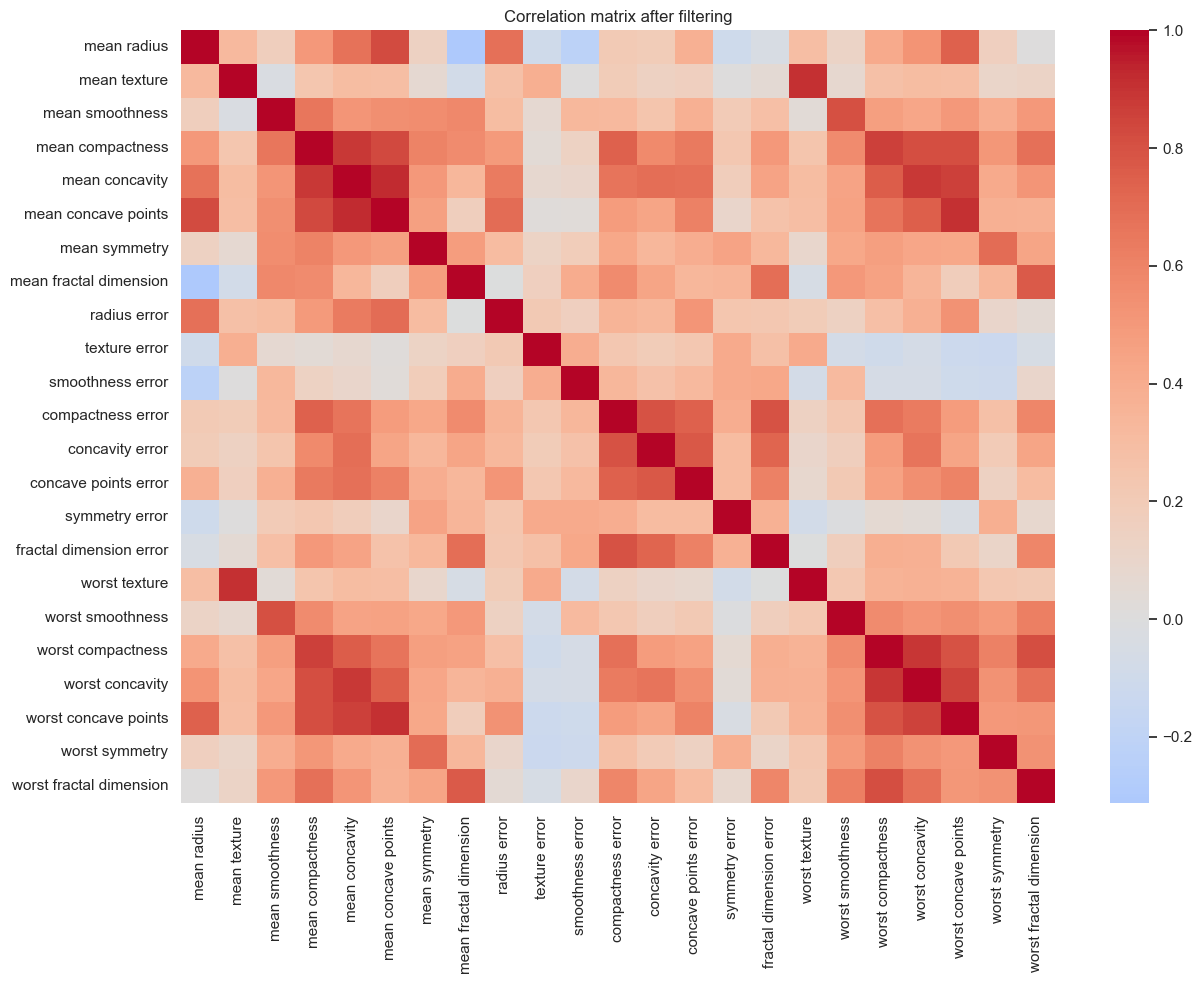

In [7]:
corr = X_raw.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax, xticklabels=True, yticklabels=True)
ax.set_title("Feature correlation matrix before correlation filtering")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "correlation_heatmap_before.png", dpi=300, bbox_inches="tight")
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr_pairs = (
    upper.stack().rename("Correlation").reset_index()
    .rename(columns={"level_0": "Feature 1", "level_1": "Feature 2"})
)
high_corr_pairs["Absolute correlation"] = high_corr_pairs["Correlation"].abs()
high_corr_pairs = high_corr_pairs[high_corr_pairs["Absolute correlation"] > CORRELATION_THRESHOLD]
high_corr_pairs = high_corr_pairs.sort_values("Absolute correlation", ascending=False)
display(high_corr_pairs)

# Greedy removal: scan columns in their original order and drop a later column
# whenever it is correlated above the threshold with an already-retained column.
# This is a transparent unsupervised filter; it does not use target labels.
upper_abs = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = [column for column in upper_abs.columns if (upper_abs[column] > CORRELATION_THRESHOLD).any()]
retained_features = [column for column in X_raw.columns if column not in to_drop]
X_corr = X_raw[retained_features].copy()

print("Correlation threshold:", CORRELATION_THRESHOLD)
print("Original feature count:", X_raw.shape[1])
print("Removed feature count:", len(to_drop))
print("Retained feature count:", X_corr.shape[1])
print("Removed features:", to_drop)
display(pd.DataFrame({"Removed feature": to_drop}))
display(X_corr.head())

corr_after = X_corr.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr_after, cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix after filtering")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "correlation_heatmap_after.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Stratified train/test split


In [8]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_corr, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)
print("Training shape:", X_train_raw.shape)
print("Test shape:", X_test_raw.shape)
display(pd.DataFrame({
    "Training count": y_train.value_counts().reindex([0, 1]).values,
    "Training proportion": y_train.value_counts(normalize=True).reindex([0, 1]).values,
    "Test count": y_test.value_counts().reindex([0, 1]).values,
    "Test proportion": y_test.value_counts(normalize=True).reindex([0, 1]).values
}, index=class_names))

Training shape: (455, 23)
Test shape: (114, 23)


,Training count,Training proportion,Test count,Test proportion
benign,285,0.626374,72,0.631579
malignant,170,0.373626,42,0.368421


## 9. Model definitions and descriptions


In [9]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
g_n_jobs = 4

In [10]:
def make_pipeline(estimator, scaled=True, feature_selection=False, k=15):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scaled:
        steps.append(("scaler", RobustScaler()))
    if feature_selection:
        steps.append(("feature_selection", SelectKBest(score_func=f_classif, k=min(k, X_train_raw.shape[1]))))
    steps.append(("model", estimator))
    return Pipeline(steps)

models = {
    "Dummy Prior Baseline": make_pipeline(DummyClassifier(strategy="prior"), scaled=False),
    "Logistic Regression": make_pipeline(LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE)),
    "Ridge Classifier": make_pipeline(RidgeClassifier(class_weight="balanced")),
    "SGD Logistic": make_pipeline(SGDClassifier(loss="log_loss", max_iter=3000, tol=1e-4, class_weight="balanced", random_state=RANDOM_STATE)),
    "Perceptron": make_pipeline(Perceptron(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE)),
    "Passive Aggressive": make_pipeline(PassiveAggressiveClassifier(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE)),
    "Decision Tree": make_pipeline(DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE), scaled=False),
    "Extra Tree": make_pipeline(ExtraTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE), scaled=False),
    "Random Forest": make_pipeline(RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE), scaled=False),
    "Extra Trees": make_pipeline(ExtraTreesClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE), scaled=False),
    "Gradient Boosting": make_pipeline(GradientBoostingClassifier(random_state=RANDOM_STATE), scaled=False),
    "Hist Gradient Boosting": make_pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE), scaled=False),
    "AdaBoost": make_pipeline(AdaBoostClassifier(n_estimators=100, random_state=RANDOM_STATE), scaled=False),
    "Bagging Tree": make_pipeline(BaggingClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE), scaled=False),
    "K-Nearest Neighbors": make_pipeline(KNeighborsClassifier(n_neighbors=5, weights="distance")),
    "SVM RBF": make_pipeline(SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=RANDOM_STATE)),
    "SVM Linear": make_pipeline(SVC(kernel="linear", probability=True, class_weight="balanced", random_state=RANDOM_STATE)),
    "Linear SVM Calibrated": make_pipeline(CalibratedClassifierCV(LinearSVC(class_weight="balanced", random_state=RANDOM_STATE), cv=3)),
    "Nu-SVM": make_pipeline(NuSVC(probability=True, class_weight="balanced", random_state=RANDOM_STATE)),
    "Gaussian Naive Bayes": make_pipeline(GaussianNB()),
    "Bernoulli Naive Bayes": make_pipeline(BernoulliNB()),
    "Linear Discriminant Analysis": make_pipeline(LinearDiscriminantAnalysis()),
    "Quadratic Discriminant Analysis": make_pipeline(QuadraticDiscriminantAnalysis(reg_param=0.1)),
    "MLP Neural Network": make_pipeline(MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1200, early_stopping=True, random_state=RANDOM_STATE)),
    "Logistic Regression SelectKBest": make_pipeline(LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE), feature_selection=True, k=15),
    "Random Forest SelectKBest": make_pipeline(RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE), scaled=False, feature_selection=True, k=15)
}

model_descriptions = {
    "Dummy Prior Baseline": "Reference baseline that predicts according to training-set class proportions.",
    "Logistic Regression": "Linear probabilistic classifier with regularized log-odds.",
    "Ridge Classifier": "Linear classifier using L2-regularized least squares.",
    "SGD Logistic": "Logistic classifier optimized with stochastic gradient descent.",
    "Perceptron": "Linear threshold model trained using perceptron updates.",
    "Passive Aggressive": "Online-style linear classifier designed for large-margin updates.",
    "Decision Tree": "Single tree that learns feature-based decision rules.",
    "Extra Tree": "Single randomized decision tree.",
    "Random Forest": "Bagged decision trees with random feature subsets.",
    "Extra Trees": "Tree ensemble with additional split randomization.",
    "Gradient Boosting": "Sequential ensemble that adds trees to correct prior errors.",
    "Hist Gradient Boosting": "Histogram-based gradient-boosted tree ensemble.",
    "AdaBoost": "Sequential ensemble that increases emphasis on difficult training cases.",
    "Bagging Tree": "Bootstrap aggregation of independently fitted base estimators.",
    "K-Nearest Neighbors": "Predicts from labels of nearby training observations.",
    "SVM RBF": "Nonlinear maximum-margin classifier with an RBF kernel.",
    "SVM Linear": "Maximum-margin classifier with a linear kernel.",
    "Linear SVM Calibrated": "Linear SVM with cross-validated probability calibration.",
    "Nu-SVM": "SVM variant whose nu parameter controls support-vector and margin-error proportions.",
    "Gaussian Naive Bayes": "Bayesian classifier assuming Gaussian class-conditional feature distributions.",
    "Bernoulli Naive Bayes": "Naive Bayes classifier designed for binary-valued features.",
    "Linear Discriminant Analysis": "Linear decision boundary based on class-conditional distributions.",
    "Quadratic Discriminant Analysis": "Quadratic decision boundary with class-specific covariance estimates.",
    "MLP Neural Network": "Feed-forward neural network with two hidden layers.",
    "Logistic Regression SelectKBest": "Logistic regression after univariate ANOVA feature selection.",
    "Random Forest SelectKBest": "Random forest after univariate ANOVA feature selection."
}
display(pd.DataFrame({"Model": list(models), "Description": [model_descriptions[n] for n in models]}))
print("Number of models:", len(models))

,Model,Description
0,Dummy Prior Baseline,Reference baseline that predicts according to ...
1,Logistic Regression,Linear probabilistic classifier with regulariz...
2,Ridge Classifier,Linear classifier using L2-regularized least s...
3,SGD Logistic,Logistic classifier optimized with stochastic ...
4,Perceptron,Linear threshold model trained using perceptro...
5,Passive Aggressive,Online-style linear classifier designed for la...
6,Decision Tree,Single tree that learns feature-based decision...
7,Extra Tree,Single randomized decision tree.
8,Random Forest,Bagged decision trees with random feature subs...
9,Extra Trees,Tree ensemble with additional split randomizat...


Number of models: 26


## 10. Fit models and compute evaluation metrics


In [11]:
def get_score_vector(fitted_model, X):
    if hasattr(fitted_model, "predict_proba"):
        probabilities = fitted_model.predict_proba(X)
        classes = list(fitted_model.classes_)
        return probabilities[:, classes.index(1)]
    if hasattr(fitted_model, "decision_function"):
        scores = np.asarray(fitted_model.decision_function(X))
        if scores.ndim == 2:
            scores = scores[:, list(fitted_model.classes_).index(1)]
        return scores.ravel()
    return np.asarray(fitted_model.predict(X), dtype=float)

results = []
fitted_models = {}
predictions = {}
score_vectors = {}
probability_vectors = {}
fit_times = {}
predict_times = {}
failed_models = {}

for name, pipeline in models.items():
    try:
        start = time.perf_counter()
        pipeline.fit(X_train_raw, y_train)
        fit_time = time.perf_counter() - start

        start = time.perf_counter()
        pred = pipeline.predict(X_test_raw)
        predict_time = time.perf_counter() - start

        scores = get_score_vector(pipeline, X_test_raw)
        if hasattr(pipeline, "predict_proba"):
            proba_all = pipeline.predict_proba(X_test_raw)
            pos_index = list(pipeline.classes_).index(1)
            proba = proba_all[:, pos_index]
            auc = roc_auc_score(y_test, proba)
            ap = average_precision_score(y_test, proba)
            ll = log_loss(y_test, proba_all, labels=list(pipeline.classes_))
            brier = brier_score_loss(y_test, proba)
            probability_vectors[name] = proba
        else:
            auc = roc_auc_score(y_test, scores)
            ap = average_precision_score(y_test, scores)
            ll = np.nan
            brier = np.nan

        results.append({
            "Model": name,
            "Accuracy": accuracy_score(y_test, pred),
            "Balanced Accuracy": balanced_accuracy_score(y_test, pred),
            "Precision (malignant)": precision_score(y_test, pred, pos_label=1, zero_division=0),
            "Detection Rate / Recall (malignant)": recall_score(y_test, pred, pos_label=1, zero_division=0),
            "Specificity (benign)": recall_score(y_test, pred, pos_label=0, zero_division=0),
            "F1 (malignant)": f1_score(y_test, pred, pos_label=1, zero_division=0),
            "Macro F1": f1_score(y_test, pred, average="macro", zero_division=0),
            "Weighted F1": f1_score(y_test, pred, average="weighted", zero_division=0),
            "ROC AUC": auc,
            "Average Precision": ap,
            "Log Loss": ll,
            "Brier Score": brier,
            "MCC": matthews_corrcoef(y_test, pred),
            "Cohen Kappa": cohen_kappa_score(y_test, pred),
            "Fit Time (s)": fit_time,
            "Prediction Time (s)": predict_time
        })
        fitted_models[name] = pipeline
        predictions[name] = pred
        score_vectors[name] = scores
        fit_times[name] = fit_time
        predict_times[name] = predict_time
    except Exception as exc:
        failed_models[name] = f"{type(exc).__name__}: {exc}"
        print(f"Model failed: {name}: {type(exc).__name__}: {exc}")

results_df = pd.DataFrame(results).sort_values("ROC AUC", ascending=False).reset_index(drop=True)
display(results_df.round(4))
results_df.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
print("Successfully fitted models:", len(fitted_models))
print("Failed models:", failed_models if failed_models else "None")

,Model,Accuracy,Balanced Accuracy,Precision (malignant),Detection Rate / Recall (malignant),Specificity (benign),F1 (malignant),Macro F1,Weighted F1,ROC AUC,Average Precision,Log Loss,Brier Score,MCC,Cohen Kappa,Fit Time (s),Prediction Time (s)
0,Extra Trees,0.9737,0.9692,0.9756,0.9524,0.9861,0.9639,0.9716,0.9736,0.9965,0.9947,0.1300,0.0320,0.9433,0.9432,0.3315,0.0393
1,Logistic Regression,0.9737,0.9692,0.9756,0.9524,0.9861,0.9639,0.9716,0.9736,0.9954,0.9933,0.0869,0.0238,0.9433,0.9432,0.0295,0.0017
2,Linear Discriminant Analysis,0.9649,0.9524,1.0000,0.9048,1.0000,0.9500,0.9615,0.9645,0.9950,0.9933,0.1144,0.0316,0.9258,0.9231,0.0290,0.0015
3,Logistic Regression SelectKBest,0.9649,0.9623,0.9524,0.9524,0.9722,0.9524,0.9623,0.9649,0.9950,0.9928,0.0877,0.0238,0.9246,0.9246,0.0140,0.0025
4,SVM Linear,0.9561,0.9454,0.9744,0.9048,0.9861,0.9383,0.9521,0.9558,0.9940,0.9915,0.1018,0.0293,0.9058,0.9043,0.0170,0.0020
5,Random Forest,0.9561,0.9454,0.9744,0.9048,0.9861,0.9383,0.9521,0.9558,0.9939,0.9907,0.1321,0.0352,0.9058,0.9043,0.3629,0.0385
6,Random Forest SelectKBest,0.9561,0.9454,0.9744,0.9048,0.9861,0.9383,0.9521,0.9558,0.9939,0.9901,0.1263,0.0348,0.9058,0.9043,0.5692,0.0417
7,Ridge Classifier,0.9825,0.9762,1.0000,0.9524,1.0000,0.9756,0.9810,0.9824,0.9937,0.9912,NaN,NaN,0.9626,0.9619,0.0262,0.0021
8,SVM RBF,0.9649,0.9573,0.9750,0.9286,0.9861,0.9512,0.9619,0.9647,0.9934,0.9912,0.0897,0.0242,0.9245,0.9238,0.0338,0.0032
9,Quadratic Discriminant Analysis,0.9474,0.9335,0.9737,0.8810,0.9861,0.9250,0.9422,0.9468,0.9931,0.9879,0.1284,0.0393,0.8872,0.8846,0.0089,0.0016


Successfully fitted models: 26
Failed models: None


## 11. Classification reports


In [12]:
for name in fitted_models:
    print("\nModel:", name)
    print(classification_report(
        y_test, predictions[name], labels=[0, 1],
        target_names=class_names, digits=4, zero_division=0
    ))


Model: Dummy Prior Baseline
              precision    recall  f1-score   support

      benign     0.6316    1.0000    0.7742        72
   malignant     0.0000    0.0000    0.0000        42

    accuracy                         0.6316       114
   macro avg     0.3158    0.5000    0.3871       114
weighted avg     0.3989    0.6316    0.4890       114


Model: Logistic Regression
              precision    recall  f1-score   support

      benign     0.9726    0.9861    0.9793        72
   malignant     0.9756    0.9524    0.9639        42

    accuracy                         0.9737       114
   macro avg     0.9741    0.9692    0.9716       114
weighted avg     0.9737    0.9737    0.9736       114


Model: Ridge Classifier
              precision    recall  f1-score   support

      benign     0.9730    1.0000    0.9863        72
   malignant     1.0000    0.9524    0.9756        42

    accuracy                         0.9825       114
   macro avg     0.9865    0.9762    0.9810   

## 12. Confusion matrices as heatmaps


In [ ]:
n_models = len(fitted_models)
ncols = 4
nrows = int(np.ceil(n_models / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.5 * nrows))
axes = np.array(axes).reshape(-1)

for ax, name in zip(axes, fitted_models):
    cm = confusion_matrix(y_test, predictions[name], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")

for ax in axes[n_models:]:
    ax.axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

## 13. ROC curves


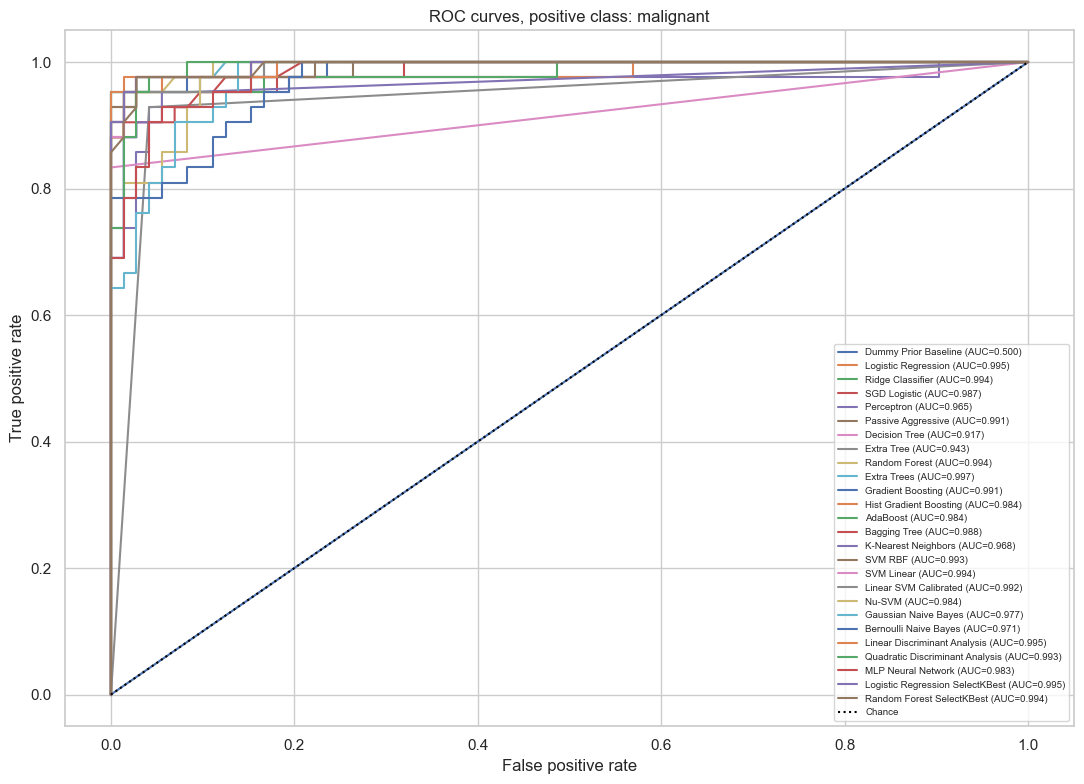

In [ ]:
fig, ax = plt.subplots(figsize=(11, 8))
for name in fitted_models:
    fpr, tpr, _ = roc_curve(y_test, score_vectors[name])
    auc_value = roc_auc_score(y_test, score_vectors[name])
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc_value:.3f})")
ax.plot([0, 1], [0, 1], linestyle=":", color="black", label="Chance")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves, positive class: malignant")
ax.legend(loc="lower right", fontsize=7)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_curves.png", dpi=300, bbox_inches="tight")
plt.show()

## 14. Precision-recall curves


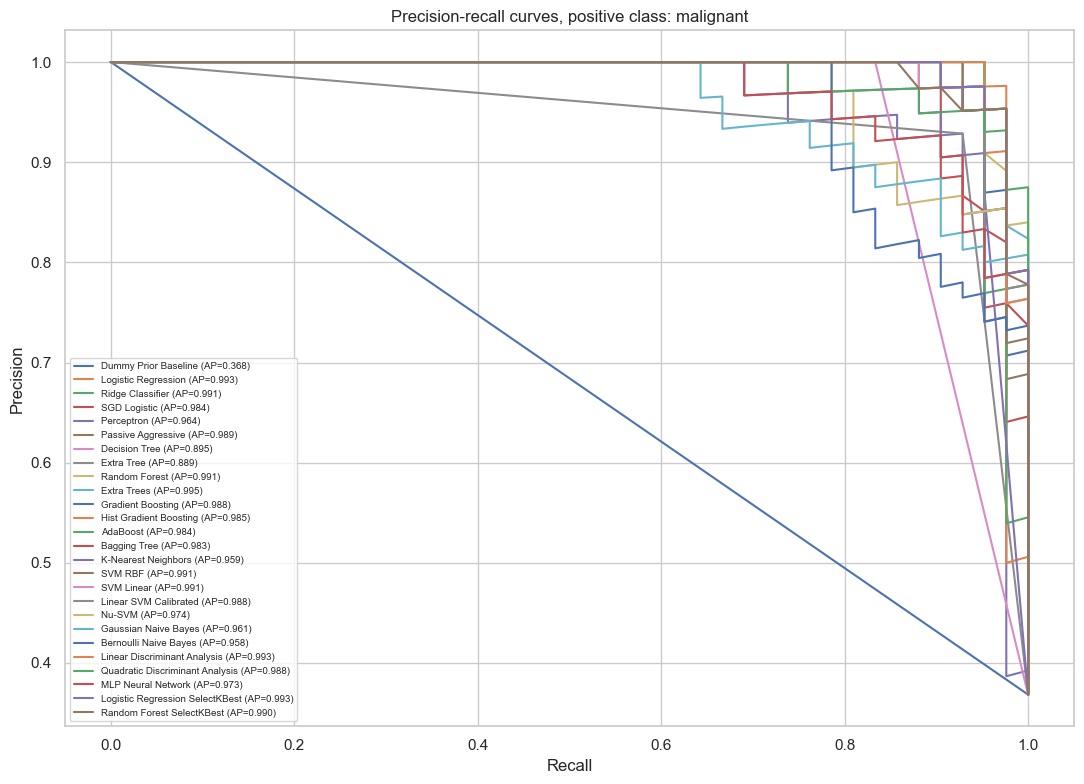

In [ ]:
fig, ax = plt.subplots(figsize=(11, 8))
for name in fitted_models:
    precision, recall, _ = precision_recall_curve(y_test, score_vectors[name])
    ap = average_precision_score(y_test, score_vectors[name])
    ax.plot(recall, precision, label=f"{name} (AP={ap:.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-recall curves, positive class: malignant")
ax.legend(loc="best", fontsize=7)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "precision_recall_curves.png", dpi=300, bbox_inches="tight")
plt.show()

## 15. Class-wise F1 comparison


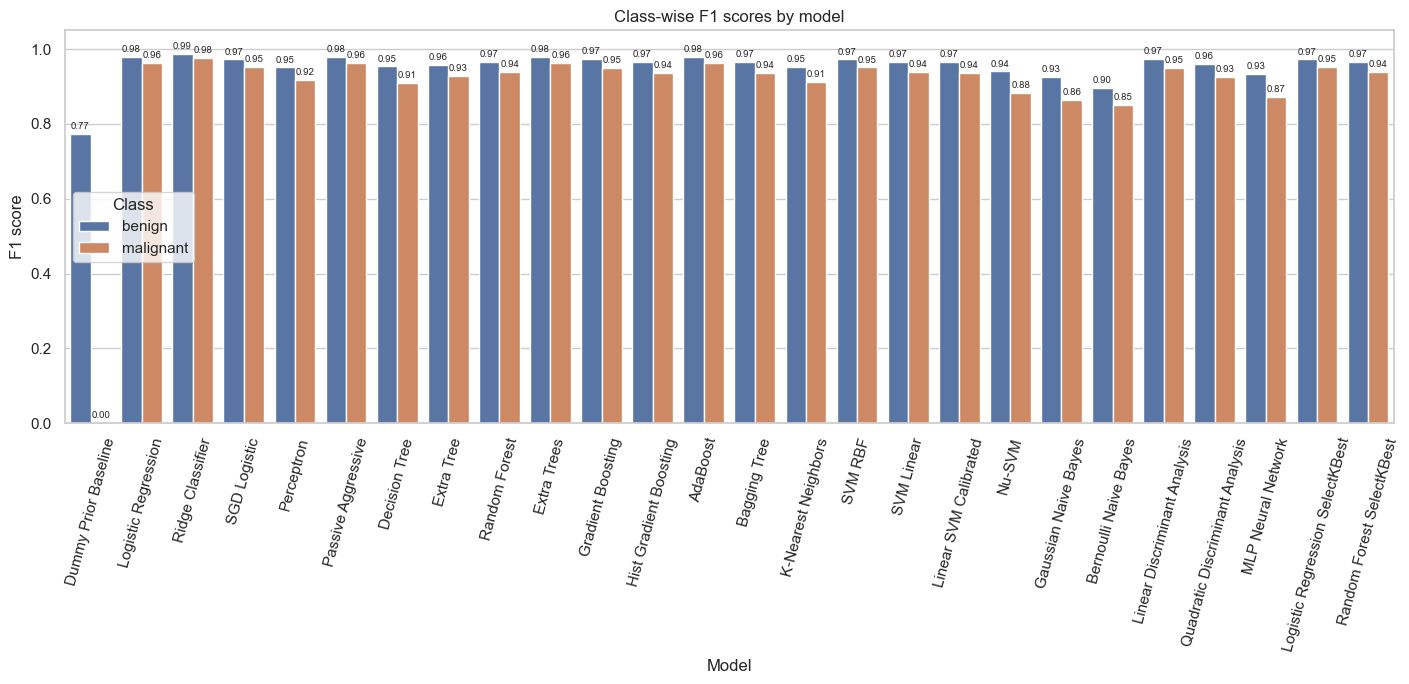

Class,benign,malignant
Model,,
AdaBoost,0.9796,0.9630
Bagging Tree,0.9664,0.9367
Bernoulli Naive Bayes,0.8955,0.8511
Decision Tree,0.9536,0.9091
Dummy Prior Baseline,0.7742,0.0000
Extra Tree,0.9583,0.9286
Extra Trees,0.9793,0.9639
Gaussian Naive Bayes,0.9252,0.8642
Gradient Boosting,0.9730,0.9500


In [ ]:
classwise_rows = []
for name in fitted_models:
    for label, class_name in [(0, "benign"), (1, "malignant")]:
        classwise_rows.append({
            "Model": name,
            "Class": class_name,
            "F1": f1_score(y_test, predictions[name], labels=[label], average="macro", zero_division=0)
        })
classwise_df = pd.DataFrame(classwise_rows)
fig, ax = plt.subplots(figsize=(max(13, len(fitted_models) * 0.55), 7))
sns.barplot(data=classwise_df, x="Model", y="F1", hue="Class", ax=ax)
ax.set_ylim(0, 1.05)
ax.set_title("Class-wise F1 scores by model")
ax.set_xlabel("Model")
ax.set_ylabel("F1 score")
ax.tick_params(axis="x", rotation=75)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=7, padding=2)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "classwise_f1.png", dpi=300, bbox_inches="tight")
plt.show()
display(classwise_df.pivot(index="Model", columns="Class", values="F1").round(4))

## 16. Main metric comparison


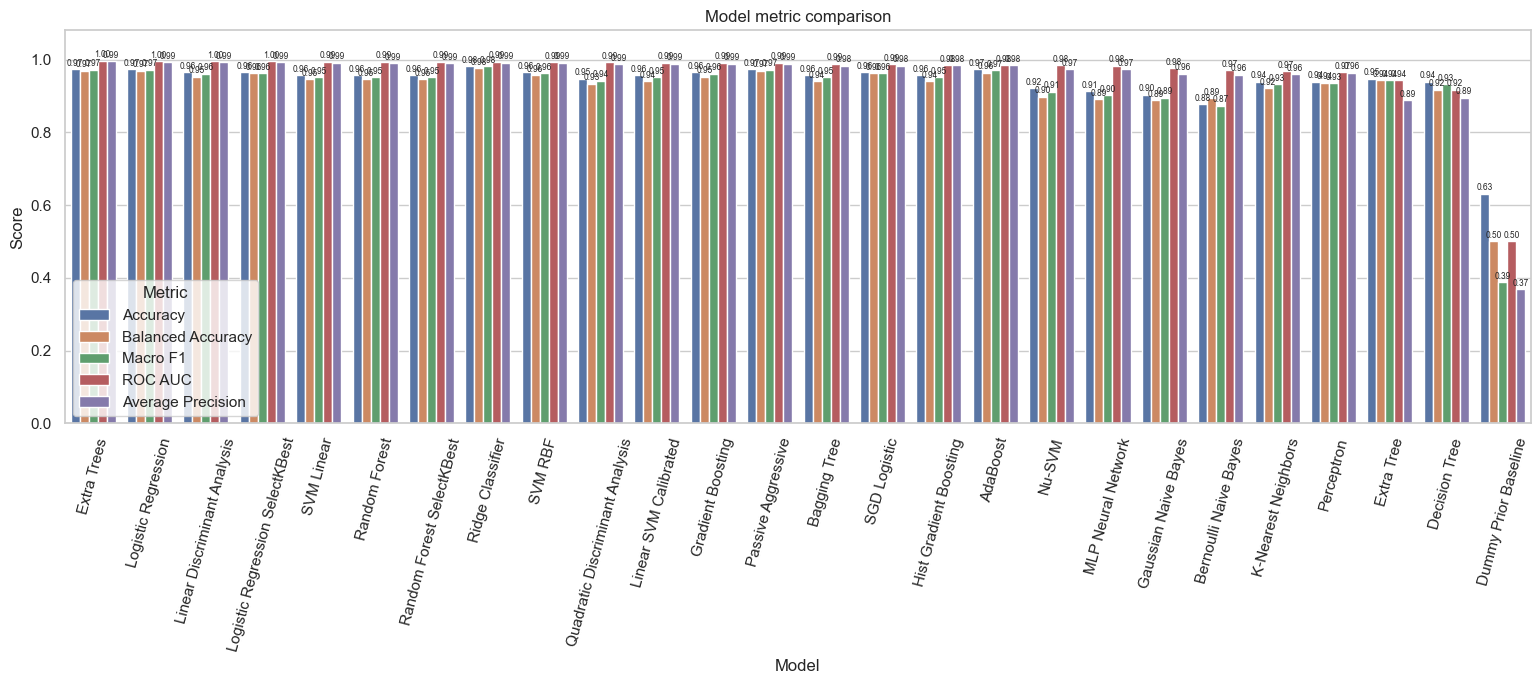

In [ ]:
metric_cols = ["Accuracy", "Balanced Accuracy", "Macro F1", "ROC AUC", "Average Precision"]
long_metrics = results_df[["Model"] + metric_cols].melt(
    id_vars="Model", var_name="Metric", value_name="Score"
)
fig, ax = plt.subplots(figsize=(max(14, len(fitted_models) * 0.6), 7))
sns.barplot(data=long_metrics, x="Model", y="Score", hue="Metric", ax=ax)
ax.set_ylim(0, 1.08)
ax.set_title("Model metric comparison")
ax.tick_params(axis="x", rotation=75)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=6, padding=1)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "metric_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## 17. Learning curves


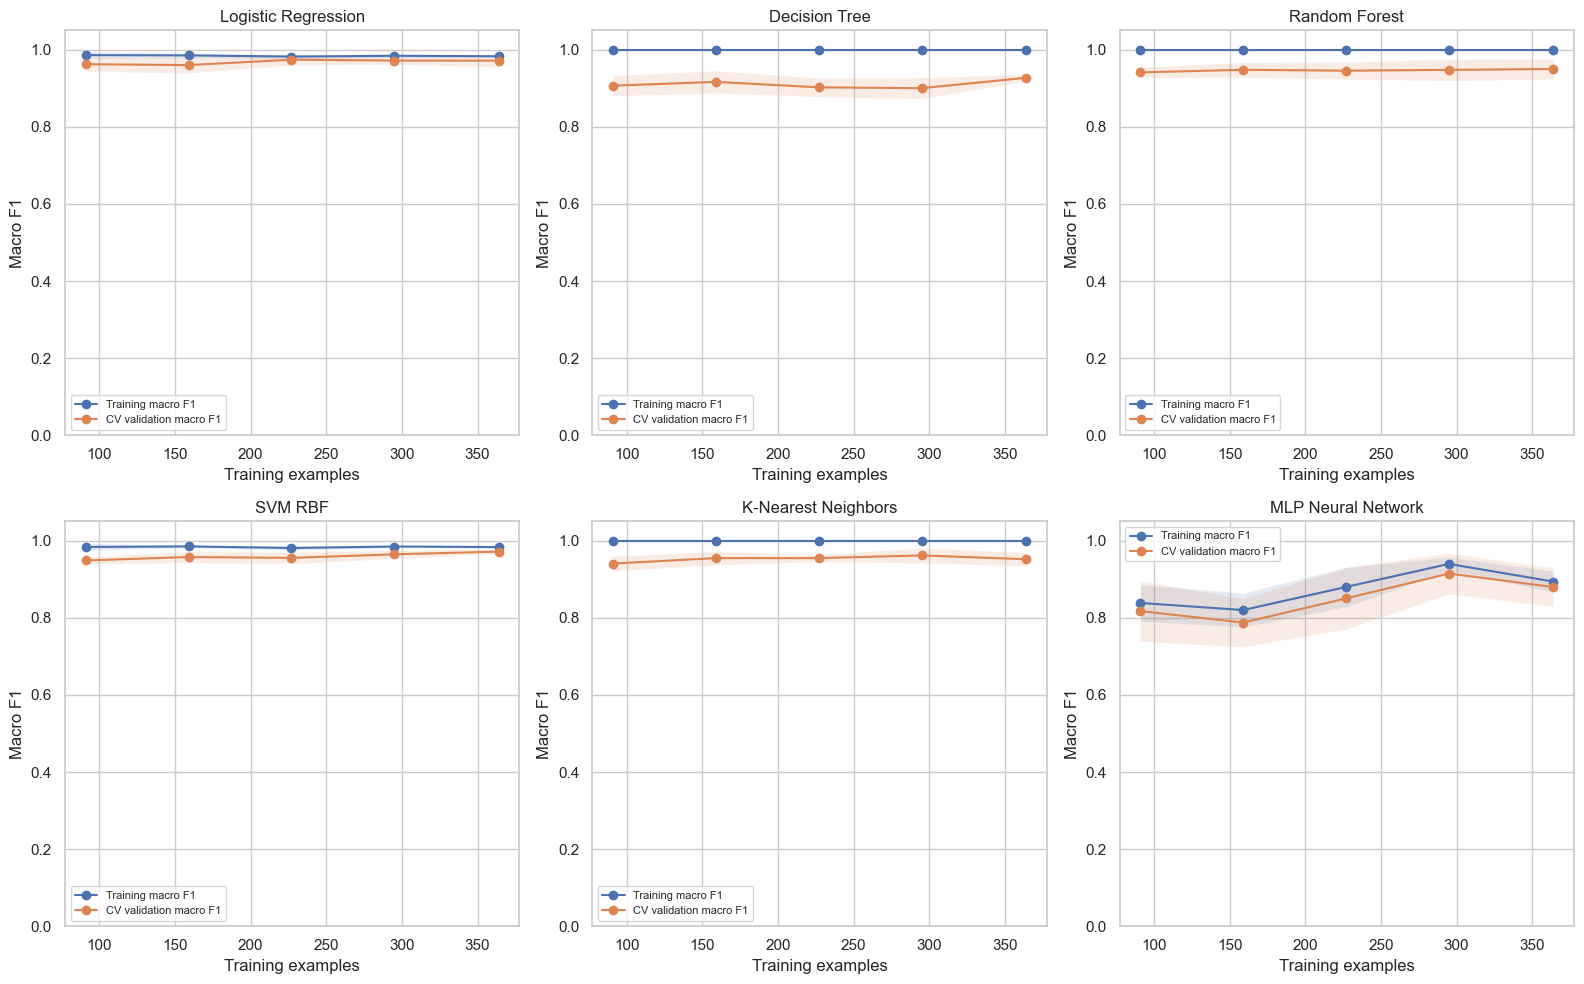

In [ ]:
# Classical scikit-learn estimators do not consistently expose epoch-wise training loss.
# Learning curves show training and cross-validation macro F1 as training data increases.
learning_curve_models = [
    name for name in [
        "Logistic Regression", "Decision Tree", "Random Forest",
        "SVM RBF", "K-Nearest Neighbors", "MLP Neural Network"
    ] if name in fitted_models
]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, name in zip(axes.flat, learning_curve_models):
    sizes, train_scores, valid_scores = learning_curve(
        models[name], X_train_raw, y_train, cv=cv, scoring="f1_macro",
        n_jobs=-1, train_sizes=np.linspace(0.25, 1.0, 5)
    )
    ax.plot(sizes, train_scores.mean(axis=1), marker="o", label="Training macro F1")
    ax.plot(sizes, valid_scores.mean(axis=1), marker="o", label="CV validation macro F1")
    ax.fill_between(sizes, train_scores.mean(axis=1) - train_scores.std(axis=1),
                    train_scores.mean(axis=1) + train_scores.std(axis=1), alpha=0.15)
    ax.fill_between(sizes, valid_scores.mean(axis=1) - valid_scores.std(axis=1),
                    valid_scores.mean(axis=1) + valid_scores.std(axis=1), alpha=0.15)
    ax.set_title(name)
    ax.set_xlabel("Training examples")
    ax.set_ylabel("Macro F1")
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8)
for ax in axes.flat[len(learning_curve_models):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "learning_curves.png", dpi=300, bbox_inches="tight")
plt.show()

## 18. Cross-validation comparison on training data


In [ ]:
cv_rows = []
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "f1_macro": "f1_macro",
    "roc_auc": "roc_auc"
}
for name, estimator in models.items():
    try:
        scores = cross_validate(
            estimator, X_train_raw, y_train, cv=cv, scoring=scoring,
            n_jobs=-1, return_train_score=False, error_score="raise"
        )
        cv_rows.append({
            "Model": name,
            "CV Accuracy Mean": scores["test_accuracy"].mean(),
            "CV Accuracy SD": scores["test_accuracy"].std(),
            "CV Balanced Accuracy Mean": scores["test_balanced_accuracy"].mean(),
            "CV Macro F1 Mean": scores["test_f1_macro"].mean(),
            "CV ROC AUC Mean": scores["test_roc_auc"].mean(),
            "CV Fit Time Mean (s)": scores["fit_time"].mean()
        })
    except Exception as exc:
        cv_rows.append({"Model": name, "CV Error": f"{type(exc).__name__}: {exc}"})

cv_results_df = pd.DataFrame(cv_rows)
display(cv_results_df.round(4))
cv_results_df.to_csv(OUTPUT_DIR / "cross_validation_comparison.csv", index=False)

,Model,CV Accuracy Mean,CV Accuracy SD,CV Balanced Accuracy Mean,CV Macro F1 Mean,CV ROC AUC Mean,CV Fit Time Mean (s)
0,Dummy Prior Baseline,0.6264,0.0000,0.5000,0.3851,0.5000,0.0088
1,Logistic Regression,0.9736,0.0149,0.9695,0.9716,0.9938,0.0165
2,Ridge Classifier,0.9582,0.0128,0.9489,0.9547,0.9922,0.0176
3,SGD Logistic,0.9582,0.0128,0.9584,0.9556,0.9891,0.0195
4,Perceptron,0.9495,0.0054,0.9525,0.9466,0.9902,0.0143
5,Passive Aggressive,0.9714,0.0054,0.9713,0.9696,0.9927,0.0125
6,Decision Tree,0.9319,0.0082,0.9266,0.9271,0.9266,0.0124
7,Extra Tree,0.9033,0.0189,0.8908,0.8952,0.8908,0.0084
8,Random Forest,0.9538,0.0245,0.9454,0.9500,0.9899,0.5244
9,Extra Trees,0.9648,0.0189,0.9553,0.9617,0.9932,0.3619


## 19. Feature selection results


,Feature,ANOVA F score,Selected
20,worst concave points,733.724933,True
5,mean concave points,684.526845,True
0,mean radius,511.274848,True
4,mean concavity,397.592082,True
19,worst concavity,319.507776,True
3,mean compactness,263.564326,True
18,worst compactness,238.203725,True
8,radius error,205.433206,True
16,worst texture,126.119113,True
17,worst smoothness,103.723265,True


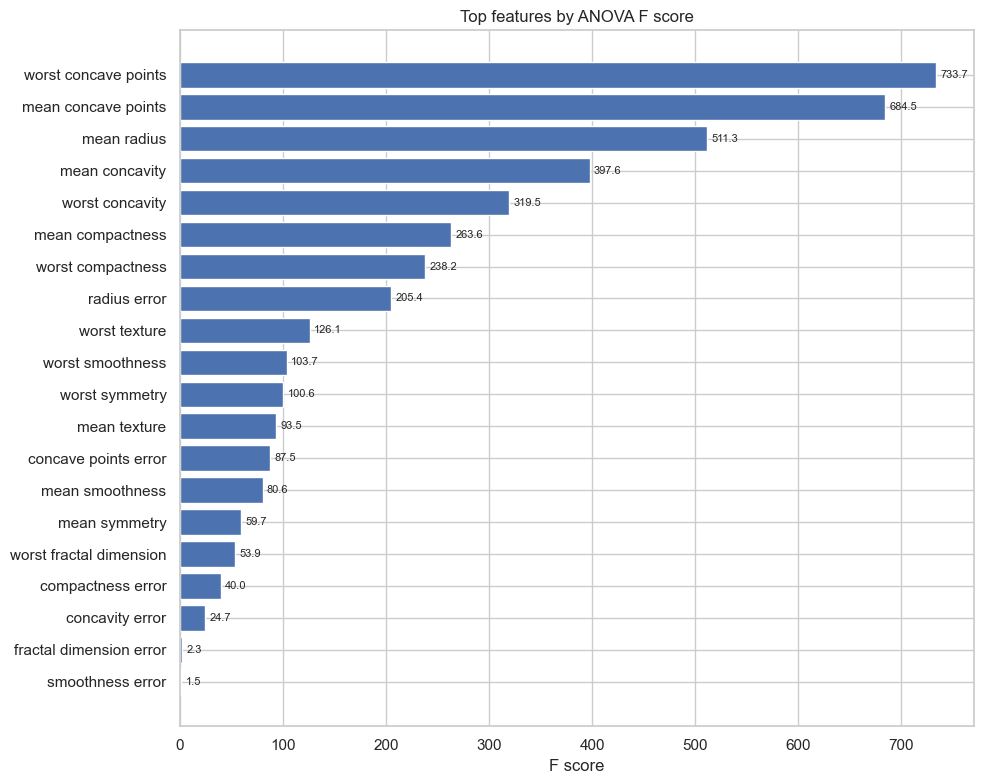

In [ ]:
# Fit selection on training data only. This table is a descriptive ANOVA ranking.
imputer_for_selection = SimpleImputer(strategy="median")
X_train_imputed = imputer_for_selection.fit_transform(X_train_raw)
selector = SelectKBest(score_func=f_classif, k=min(15, X_train_raw.shape[1]))
selector.fit(X_train_imputed, y_train)

selected_features_df = pd.DataFrame({
    "Feature": X_train_raw.columns,
    "ANOVA F score": selector.scores_,
    "Selected": selector.get_support()
}).sort_values("ANOVA F score", ascending=False)
display(selected_features_df)
selected_features_df.to_csv(OUTPUT_DIR / "feature_selection_anova.csv", index=False)

selected_plot = selected_features_df.head(20).sort_values("ANOVA F score")
fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.barh(selected_plot["Feature"], selected_plot["ANOVA F score"])
ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=8)
ax.set_title("Top features by ANOVA F score")
ax.set_xlabel("F score")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "anova_feature_scores.png", dpi=300, bbox_inches="tight")
plt.show()

## 20. Select a model for explanatory analysis


In [ ]:
# This automatic selection is for demonstration. For publication, choose the model by
# training-only cross-validation and evaluate the chosen model once on the test set.
# Here, select by mean CV ROC AUC when available, not by held-out test performance.
cv_auc = cv_results_df.dropna(subset=["CV ROC AUC Mean"]).sort_values("CV ROC AUC Mean", ascending=False)
if len(cv_auc):
    selected_model_name = cv_auc.iloc[0]["Model"]
else:
    selected_model_name = results_df.iloc[0]["Model"]

if selected_model_name not in fitted_models:
    selected_model_name = results_df.iloc[0]["Model"]

selected_model = fitted_models[selected_model_name]
print("Selected model for explanatory analysis:", selected_model_name)
print("Description:", model_descriptions[selected_model_name])
print("Selection is illustrative. Report a prespecified training-CV protocol in research.")

Selected model for explanatory analysis: AdaBoost
Description: Sequential ensemble that increases emphasis on difficult training cases.
Selection is illustrative. Report a prespecified training-CV protocol in research.


## 21. Permutation feature importance


,Feature,Importance mean,Importance SD
8,radius error,0.056246,0.019395
16,worst texture,0.045185,0.010952
0,mean radius,0.044348,0.019462
20,worst concave points,0.041430,0.013574
19,worst concavity,0.033717,0.009771
1,mean texture,0.017976,0.009366
5,mean concave points,0.010423,0.004287
2,mean smoothness,0.004577,0.006073
3,mean compactness,0.002389,0.006424
21,worst symmetry,0.001249,0.003184


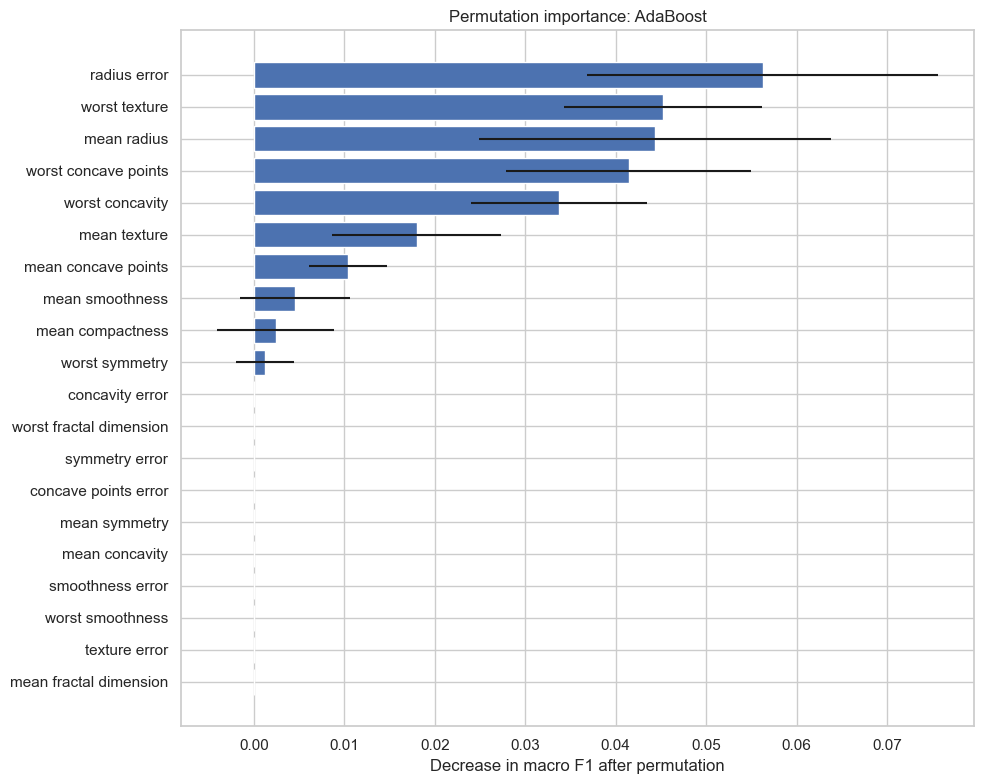

In [ ]:
perm = permutation_importance(
    selected_model, X_test_raw, y_test, scoring="f1_macro",
    n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1
)
importance_df = pd.DataFrame({
    "Feature": X_test_raw.columns,
    "Importance mean": perm.importances_mean,
    "Importance SD": perm.importances_std
}).sort_values("Importance mean", ascending=False)
display(importance_df.head(20))
importance_df.to_csv(OUTPUT_DIR / "permutation_importance.csv", index=False)

top_imp = importance_df.head(20).sort_values("Importance mean")
fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.barh(top_imp["Feature"], top_imp["Importance mean"], xerr=top_imp["Importance SD"])
ax.set_title(f"Permutation importance: {selected_model_name}")
ax.set_xlabel("Decrease in macro F1 after permutation")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "permutation_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

## 22. SHAP explanations for the selected model


In [ ]:
%pip install shap

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ------------- -------------------------- 262.1/755.4 kB ? eta -:--:--
   --------------------------- ------------ 524.3/755.4 kB 2.2 MB/s eta 0:00:01
   ---------------------------------------- 755.4/755.4 kB 1.1 MB/s eta 0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------

Primary SHAP explainer failed: InvalidModelError Model type not yet supported by TreeExplainer: <class 'sklearn.ensemble._weight_boosting.AdaBoostClassifier'>


  0%|          | 0/60 [00:00<?, ?it/s]

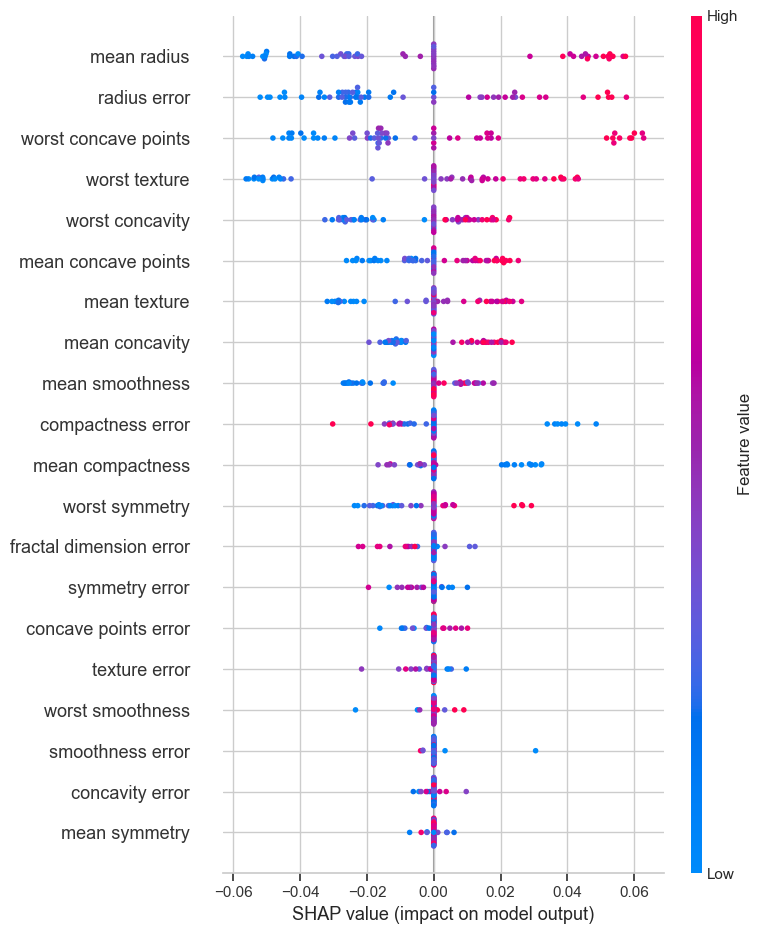

,Feature,Mean absolute SHAP
0,mean radius,0.032559
8,radius error,0.027318
20,worst concave points,0.026566
16,worst texture,0.023457
19,worst concavity,0.013877
5,mean concave points,0.011397
1,mean texture,0.011207
4,mean concavity,0.009857
2,mean smoothness,0.009196
11,compactness error,0.007767


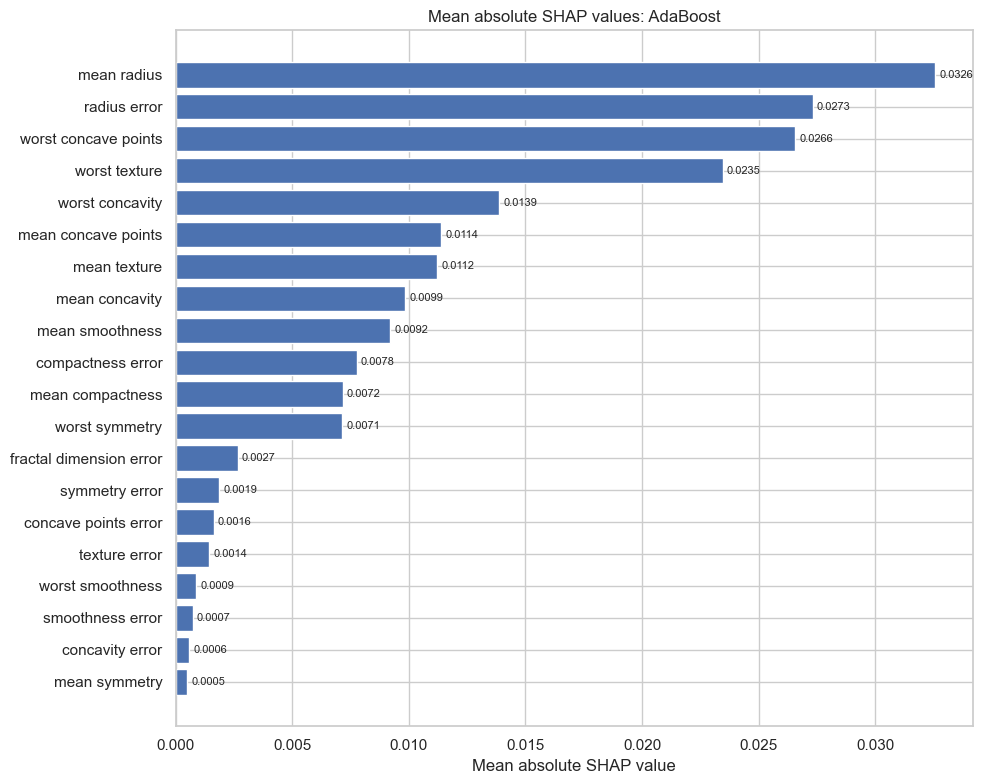

In [ ]:
# Install SHAP if needed in your environment: %pip install shap
# SHAP support varies by model. TreeExplainer is attempted for tree models, otherwise
# a model-agnostic KernelExplainer is used on a small background/sample set.
# KernelExplainer can be slow, so sample sizes are intentionally capped.
try:
    import shap

    final_estimator = selected_model.named_steps["model"]
    has_selector = "feature_selection" in selected_model.named_steps
    has_scaler = "scaler" in selected_model.named_steps
    has_imputer = "imputer" in selected_model.named_steps

    def transform_for_model(X_frame):
        transformed = X_frame
        if has_imputer:
            transformed = selected_model.named_steps["imputer"].transform(transformed)
        if has_scaler:
            transformed = selected_model.named_steps["scaler"].transform(transformed)
        if has_selector:
            transformed = selected_model.named_steps["feature_selection"].transform(transformed)
        return transformed

    transformed_train = transform_for_model(X_train_raw)
    transformed_test = transform_for_model(X_test_raw)
    if has_selector:
        shap_feature_names = list(X_train_raw.columns[selected_model.named_steps["feature_selection"].get_support()])
    else:
        shap_feature_names = list(X_train_raw.columns)

    background_n = min(40, len(transformed_train))
    explain_n = min(60, len(transformed_test))
    rng = np.random.default_rng(RANDOM_STATE)
    background_idx = rng.choice(len(transformed_train), size=background_n, replace=False)
    explain_idx = rng.choice(len(transformed_test), size=explain_n, replace=False)
    background = transformed_train[background_idx]
    explain_data = transformed_test[explain_idx]

    tree_model_names = {
        "Decision Tree", "Extra Tree", "Random Forest", "Extra Trees",
        "Gradient Boosting", "Hist Gradient Boosting", "AdaBoost",
        "Bagging Tree", "Random Forest SelectKBest"
    }

    shap_values = None
    try:
        if selected_model_name in tree_model_names:
            explainer = shap.TreeExplainer(final_estimator)
            shap_values = explainer.shap_values(explain_data)
        else:
            if hasattr(final_estimator, "predict_proba"):
                predict_function = final_estimator.predict_proba
                def positive_probability(arr):
                    probabilities = predict_function(arr)
                    return probabilities[:, list(final_estimator.classes_).index(1)]
            elif hasattr(final_estimator, "decision_function"):
                def positive_probability(arr):
                    scores = np.asarray(final_estimator.decision_function(arr))
                    if scores.ndim == 2:
                        return scores[:, list(final_estimator.classes_).index(1)]
                    return scores
            else:
                def positive_probability(arr):
                    return final_estimator.predict(arr).astype(float)

            explainer = shap.KernelExplainer(positive_probability, background)
            shap_values = explainer.shap_values(explain_data, nsamples=100)
    except Exception as explain_error:
        print("Primary SHAP explainer failed:", type(explain_error).__name__, explain_error)
        if hasattr(final_estimator, "predict_proba"):
            def positive_probability(arr):
                probabilities = final_estimator.predict_proba(arr)
                return probabilities[:, list(final_estimator.classes_).index(1)]
        elif hasattr(final_estimator, "decision_function"):
            def positive_probability(arr):
                return np.asarray(final_estimator.decision_function(arr)).ravel()
        else:
            def positive_probability(arr):
                return final_estimator.predict(arr).astype(float)
        explainer = shap.KernelExplainer(positive_probability, background)
        shap_values = explainer.shap_values(explain_data, nsamples=80)

    # Normalize different SHAP API return formats into a 2D array.
    if isinstance(shap_values, list):
        shap_matrix = np.asarray(shap_values[-1])
    else:
        shap_matrix = np.asarray(shap_values)
        if shap_matrix.ndim == 3:
            if shap_matrix.shape[-1] == 2:
                shap_matrix = shap_matrix[:, :, 1]
            elif shap_matrix.shape[0] == 2:
                shap_matrix = shap_matrix[1]
            else:
                shap_matrix = shap_matrix[:, :, 0]
        if shap_matrix.ndim == 1:
            shap_matrix = shap_matrix.reshape(1, -1)

    if shap_matrix.shape[1] == len(shap_feature_names):
        shap.summary_plot(shap_matrix, explain_data, feature_names=shap_feature_names, show=False)
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / "shap_summary.png", dpi=300, bbox_inches="tight")
        plt.show()

        mean_abs_shap = np.abs(shap_matrix).mean(axis=0)
        shap_importance = pd.DataFrame({
            "Feature": shap_feature_names,
            "Mean absolute SHAP": mean_abs_shap
        }).sort_values("Mean absolute SHAP", ascending=False)
        display(shap_importance.head(20))

        top_shap = shap_importance.head(20).sort_values("Mean absolute SHAP")
        fig, ax = plt.subplots(figsize=(10, 8))
        bars = ax.barh(top_shap["Feature"], top_shap["Mean absolute SHAP"])
        ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=8)
        ax.set_title(f"Mean absolute SHAP values: {selected_model_name}")
        ax.set_xlabel("Mean absolute SHAP value")
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / "shap_feature_importance.png", dpi=300, bbox_inches="tight")
        plt.show()
        shap_importance.to_csv(OUTPUT_DIR / "shap_feature_importance.csv", index=False)
    else:
        print("SHAP array shape did not match the selected feature count:", shap_matrix.shape)
        print("SHAP values were computed, but the summary plot was skipped for safety.")
except ImportError:
    print("SHAP is not installed. Run %pip install shap in a notebook cell, then rerun this section.")
except Exception as shap_error:
    print("SHAP analysis could not be completed for this model.")
    print(type(shap_error).__name__ + ":", shap_error)
    print("The rest of the notebook can still run.")

## 23. Model size, stored parameters, tree nodes, and inference cost


In [ ]:
def count_numeric_parameters(obj):
    total = 0
    seen = set()
    def visit(value):
        nonlocal total
        if id(value) in seen:
            return
        seen.add(id(value))
        if isinstance(value, np.ndarray) and np.issubdtype(value.dtype, np.number):
            total += int(value.size)
        elif isinstance(value, (list, tuple)):
            for item in value:
                visit(item)
        elif isinstance(value, dict):
            for item in value.values():
                visit(item)
    for attr in [
        "coef_", "intercept_", "feature_importances_", "support_vectors_",
        "dual_coef_", "support_", "classes_", "means_", "variances_", "theta_",
        "coefs_", "intercepts_"
    ]:
        if hasattr(obj, attr):
            visit(getattr(obj, attr))
    return total

def count_tree_nodes(obj):
    total = 0
    if hasattr(obj, "tree_"):
        total += int(obj.tree_.node_count)
    if hasattr(obj, "estimators_"):
        try:
            estimators = np.asarray(obj.estimators_, dtype=object).ravel()
            for estimator in estimators:
                if estimator is not None:
                    total += count_tree_nodes(estimator)
        except Exception:
            pass
    return total

cost_rows = []
for name, pipeline in fitted_models.items():
    safe_name = "".join(ch.lower() if ch.isalnum() else "_" for ch in name).strip("_")
    model_path = OUTPUT_DIR / f"{safe_name}.joblib"
    joblib.dump(pipeline, model_path, compress=3)
    final_estimator = pipeline.named_steps["model"]
    cost_rows.append({
        "Model": name,
        "FLOPs": np.nan,
        "FLOPs note": "Not reported: no common defensible FLOP definition for these classical estimators",
        "Stored numeric values (proxy)": count_numeric_parameters(final_estimator),
        "Tree nodes (proxy)": count_tree_nodes(final_estimator),
        "Serialized size (MB)": model_path.stat().st_size / (1024 ** 2),
        "Fit time (s)": fit_times[name],
        "Prediction time (ms/sample)": 1000 * predict_times[name] / len(X_test_raw)
    })

cost_df = pd.DataFrame(cost_rows)
full_comparison = results_df.merge(cost_df, on="Model", how="left")
wanted_columns = [
    "Model", "FLOPs", "Stored numeric values (proxy)", "Tree nodes (proxy)",
    "Serialized size (MB)", "Accuracy", "F1 (malignant)", "Macro F1",
    "ROC AUC", "Detection Rate / Recall (malignant)", "Fit time (s)",
    "Prediction time (ms/sample)"
]
display(full_comparison[wanted_columns].round(5))
full_comparison.to_csv(OUTPUT_DIR / "full_model_comparison_with_cost.csv", index=False)

,Model,FLOPs,Stored numeric values (proxy),Tree nodes (proxy),Serialized size (MB),Accuracy,F1 (malignant),Macro F1,ROC AUC,Detection Rate / Recall (malignant),Fit time (s),Prediction time (ms/sample)
0,Extra Trees,NaN,25,32590,0.63289,0.97368,0.96386,0.97158,0.99653,0.95238,0.22675,0.31707
1,Logistic Regression,NaN,26,0,0.00179,0.97368,0.96386,0.97158,0.99537,0.95238,0.01963,0.01561
2,Linear Discriminant Analysis,NaN,72,0,0.00254,0.96491,0.95000,0.96149,0.99504,0.90476,0.00574,0.01054
3,Logistic Regression SelectKBest,NaN,18,0,0.00219,0.96491,0.95238,0.96230,0.99504,0.95238,0.01042,0.01457
4,SVM Linear,NaN,1126,0,0.00953,0.95614,0.93827,0.95213,0.99405,0.90476,0.01871,0.01808
5,Random Forest,NaN,25,10184,0.21612,0.95614,0.93827,0.95213,0.99388,0.90476,0.26692,0.36665
6,Random Forest SelectKBest,NaN,17,10038,0.21392,0.95614,0.93827,0.95213,0.99388,0.90476,0.28561,0.31968
7,Ridge Classifier,NaN,26,0,0.00180,0.98246,0.97561,0.98096,0.99372,0.95238,0.00812,0.01783
8,SVM RBF,NaN,3153,0,0.02296,0.96491,0.95122,0.96191,0.99339,0.92857,0.03144,0.03261
9,Quadratic Discriminant Analysis,NaN,48,0,0.01013,0.94737,0.92500,0.94223,0.99306,0.88095,0.00748,0.01315


## 24. Probability calibration curves


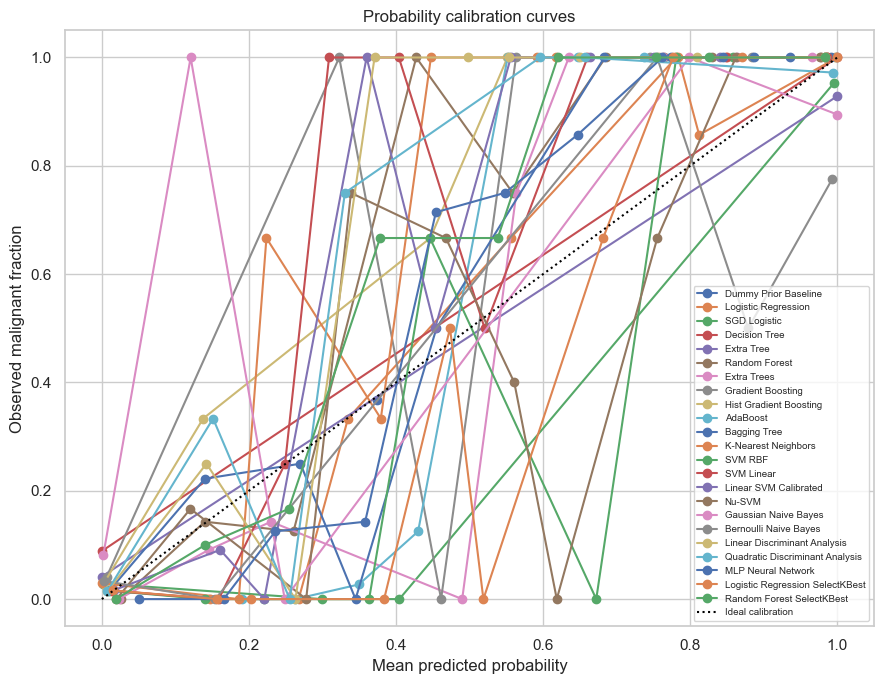

In [ ]:
probability_models = list(probability_vectors)
fig, ax = plt.subplots(figsize=(9, 7))
for name in probability_models:
    observed, predicted = calibration_curve(y_test, probability_vectors[name], n_bins=10, strategy="uniform")
    ax.plot(predicted, observed, marker="o", label=name)
ax.plot([0, 1], [0, 1], linestyle=":", color="black", label="Ideal calibration")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed malignant fraction")
ax.set_title("Probability calibration curves")
ax.legend(fontsize=7, loc="best")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "calibration_curves.png", dpi=300, bbox_inches="tight")
plt.show()

## 25. Threshold trade-off analysis


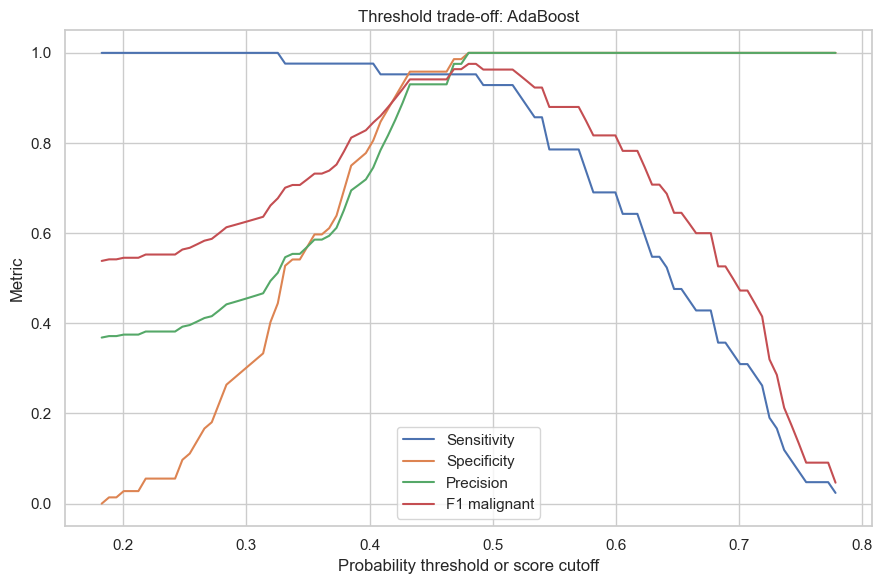

,Threshold,Sensitivity,Specificity,Precision,F1 malignant
0,0.1824,1.0000,0.0000,0.3684,0.5385
10,0.2420,1.0000,0.0556,0.3818,0.5526
20,0.3016,1.0000,0.3056,0.4565,0.6269
30,0.3612,0.9762,0.5972,0.5857,0.7321
40,0.4208,0.9524,0.9028,0.8511,0.8989
50,0.4804,0.9524,1.0000,1.0000,0.9756
60,0.5401,0.8571,1.0000,1.0000,0.9231
70,0.5997,0.6905,1.0000,1.0000,0.8169
80,0.6593,0.4524,1.0000,1.0000,0.6230
90,0.7189,0.2619,1.0000,1.0000,0.4151


Do not choose the final operating threshold from the test set. Use training-only validation.


In [ ]:
if selected_model_name in probability_vectors:
    selected_scores = probability_vectors[selected_model_name]
else:
    selected_scores = score_vectors[selected_model_name]

thresholds = np.linspace(float(np.min(selected_scores)), float(np.max(selected_scores)), 101)
threshold_rows = []
for threshold in thresholds:
    pred_threshold = (selected_scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred_threshold, labels=[0, 1]).ravel()
    threshold_rows.append({
        "Threshold": threshold,
        "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
        "Specificity": tn / (tn + fp) if tn + fp else np.nan,
        "Precision": tp / (tp + fp) if tp + fp else np.nan,
        "F1 malignant": f1_score(y_test, pred_threshold, pos_label=1, zero_division=0)
    })
threshold_df = pd.DataFrame(threshold_rows)

fig, ax = plt.subplots(figsize=(9, 6))
for column in ["Sensitivity", "Specificity", "Precision", "F1 malignant"]:
    ax.plot(threshold_df["Threshold"], threshold_df[column], label=column)
ax.set_xlabel("Probability threshold or score cutoff")
ax.set_ylabel("Metric")
ax.set_title(f"Threshold trade-off: {selected_model_name}")
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "threshold_analysis.png", dpi=300, bbox_inches="tight")
plt.show()
display(threshold_df.iloc[::10].round(4))
print("Do not choose the final operating threshold from the test set. Use training-only validation.")

## 26. Save predictions, tables, and experiment metadata


In [ ]:
prediction_table = pd.DataFrame({"y_true": y_test}, index=y_test.index)
for name in fitted_models:
    prediction_table[f"pred_{name}"] = predictions[name]
    prediction_table[f"score_{name}"] = score_vectors[name]
prediction_table.to_csv(OUTPUT_DIR / "test_predictions_all_models.csv", index=True)

metadata = {
    "dataset": "Wisconsin Diagnostic Breast Cancer from scikit-learn",
    "samples": int(X_raw.shape[0]),
    "original_features": int(X_raw.shape[1]),
    "retained_features_after_correlation_filter": int(X_corr.shape[1]),
    "correlation_threshold": CORRELATION_THRESHOLD,
    "removed_correlated_features": to_drop,
    "positive_class": "malignant",
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "models_attempted": list(models.keys()),
    "models_successful": list(fitted_models.keys()),
    "models_failed": failed_models,
    "selected_model_for_explanations": selected_model_name,
    "note": "Exploratory benchmark. Select and tune using training-only cross-validation, then report an untouched test evaluation."
}
with open(OUTPUT_DIR / "experiment_metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)

print("Saved outputs to:", OUTPUT_DIR.resolve())
print("Files include comparison tables, predictions, fitted models, and high-resolution plots.")

Saved outputs to: D:\gitProjectsTanvirAnjomSiddique\Notes_and_Practice_Code\Data_Mining_and_WareHousing_CSE4250_BAUET\Data_Mining_and_WareHousing_CSE4250_BAUET\Lab10-Classification\classification_research_outputs
Files include comparison tables, predictions, fitted models, and high-resolution plots.


## 27. Interpretation and reporting checklist

- Report the dataset source, class encoding, feature filtering rule, train/test split, random seed, and software versions.
- Report the training cross-validation mean and standard deviation, not only the single hold-out score.
- For malignant detection, report sensitivity, specificity, precision, F1, ROC AUC, and precision-recall average precision.
- Treat IQR outliers as flags, not automatic errors. Do not delete valid observations solely because they are extreme.
- The correlation filter is unsupervised and uses feature correlations only. Feature selection using target labels is fitted on training data only inside each pipeline.
- Do not report the test-set-selected model as an unbiased winner. The SHAP section explains the model selected by training-set cross-validation when available.
- FLOPs are intentionally blank because a single comparable FLOP count is not available for all the classical estimators in this notebook. Serialized size and measured inference time are directly measured; stored numeric values and tree nodes are labelled proxies.
- SHAP results are model- and sample-dependent explanations, not proof of causality.


<a id="28"></a>

<h1 style='background:#007fff;border:0; color:white;
box-shadow: 10px 10px 5px 0px rgba(0,0,0,0.25);
    transform: rotateX(10deg); border-radius: 25px;
    '><center>
        End of CSE-4250 & Begining of your new journey.
    </center>
</h1>


<div style="perspective: 1000px; padding: 10px 0;">
    <h2 style="background: linear-gradient(135deg, #007fff, #0056b3); border: 0; color: white;
        box-shadow: 0 10px 20px rgba(0,0,0,0.19), 0 6px 6px rgba(0,0,0,0.23);
        transform: rotateX(10deg); border-radius: 15px; padding: 15px; 
        text-align: center; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;
        text-shadow: 2px 2px 4px rgba(0,0,0,0.3); margin-bottom: 25px;">
        Good Luck for Your Future, My Precious Students!
    </h2>
</div>

<p style="font-size: 16px; line-height: 1.6; font-family: Arial, sans-serif;">
    It has been an absolute honor watching you grow, learn, and overcome challenges. As you step into this exciting next chapter, remember that your potential is completely limitless. 
    Believe in yourself just as much as I believe in you. Work hard, stay humble, and never stop chasing your dreams. The future belongs to you!
</p>

<br>

<p style="font-size: 16px; line-height: 1.5; font-family: Arial, sans-serif;">
    Best Regards,<br><br>
    <strong>Tanvir Anjom Siddique</strong><br>
    Lecturer, Dept. of CSE, BAUET<br>
    <span style="font-size: 14px;">Oct 14, 2026</span>
</p>
